# CredGuard-IoT — Dataset Construction

This notebook builds the final **CredGuard-IoT** dataset from five heterogeneous authentication sources.

**Pipeline**
1. Setup
2. Loading the five datasets
3. Exploratory data analysis
4. Pre-processing of each dataset (column order, data types, unified values)
5. Merging, deduplication, and missing-value handling
6. Feature engineering (behavioral, credential, and temporal features)
7. Stratified group sampling of the RBA dataset
8. Building and saving the final dataset

# 1. Setup

In [1]:
# --- Data processing ---
import os
import json
import ipaddress
import numpy as np
import pandas as pd

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

In [2]:
# ---------------- Configuration (Kaggle) ----------------
DATA_DIR = "/kaggle/input/datasets/irahfa7med/dataset-credguard/archive" 

OUTPUT_FILE = "/kaggle/working/CredGuard_IoT.csv"    # final dataset

RANDOM_STATE = 42                                    # makes the sampling reproducible

LOOKUP_CACHE = os.path.join(DATA_DIR, "ip_lookup_cache.json")   # cache file uploaded with the dataset
IPINFO_TOKEN = None   # not needed: all IPs are already in the lookup cache

# Target size of the final dataset
TARGET_NORMAL = 501_998
TARGET_ABNORMAL = 501_032
TARGET_TOTAL = TARGET_NORMAL + TARGET_ABNORMAL   # 1,003,030

# Check that all input files are found
print(os.listdir(DATA_DIR))

['SSH honeypot logs.csv', 'authV1.csv', 'ip_lookup_cache.json', 'newRBA.csv', 'ssh brute force.csv', 'web (2).csv']


In [3]:
# ---------------- Helper functions ----------------
SOURCE_NAMES = {
    "df1": "SSH honeypot logs",
    "df2": "Cowrie honeypot (authV1)",
    "df3": "RBA",
    "df4": "SSH brute force",
    "df5": "Synthetic web logs",
}

def column_report(dfs, col):
    """Print the datatype, size, missing values and a sample value of one column in every dataset."""
    rows = []
    for name, df in dfs.items():
        non_null = df[col].dropna()
        rows.append({
            "dataset": name,
            "dtype": str(df[col].dtype),
            "rows": len(df),
            "missing": int(df[col].isna().sum()),
            "sample": non_null.iloc[0] if len(non_null) else "Empty",
        })
    print(f"--- column: {col} ---")
    print(pd.DataFrame(rows).to_string(index=False))


def missing_report(df):
    """Print only the columns that still have missing values."""
    counts = df.isna().sum()
    report = pd.DataFrame({"missing": counts, "percent (%)": (counts / len(df) * 100).round(4)})
    report = report[report["missing"] > 0]
    print("No missing values." if report.empty else report)


def classify_ip_type(ip):
    """Private / Public / Empty / Invalid."""
    if pd.isna(ip) or ip == "":
        return "Empty"
    try:
        return "Private" if ipaddress.ip_address(ip).is_private else "Public"
    except ValueError:
        return "Invalid"

# 2. Loading the datasets

In [4]:
dfs = {
    "df1": pd.read_csv(os.path.join(DATA_DIR, "SSH honeypot logs.csv"), low_memory=False),
    "df2": pd.read_csv(os.path.join(DATA_DIR, "authV1.csv")),
    "df3": pd.read_csv(os.path.join(DATA_DIR, "newRBA.csv")),
    "df4": pd.read_csv(os.path.join(DATA_DIR, "ssh brute force.csv")),
    "df5": pd.read_csv(os.path.join(DATA_DIR, "web (2).csv")),
}

for name, df in dfs.items():
    print(f"{name:<4} {SOURCE_NAMES[name]:<26} {df.shape[0]:>10,} rows  x {df.shape[1]} columns")

df1  SSH honeypot logs              84,467 rows  x 8 columns
df2  Cowrie honeypot (authV1)       40,128 rows  x 8 columns
df3  RBA                         1,007,432 rows  x 8 columns
df4  SSH brute force                53,756 rows  x 8 columns
df5  Synthetic web logs             10,000 rows  x 8 columns


# 3. Exploratory data analysis

In [5]:
for name, df in dfs.items():
    print(f"=============== {name}: {SOURCE_NAMES[name]} ===============")
    df.info()
    print()

=============== df1: SSH honeypot logs ===============
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84467 entries, 0 to 84466
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   timestamp  84467 non-null  object
 1   username   84462 non-null  object
 2   src_ip     84467 non-null  object
 3   password   84320 non-null  object
 4   asn        82417 non-null  object
 5   location   42343 non-null  object
 6   status     84467 non-null  int64 
 7   label      84467 non-null  int64 
dtypes: int64(2), object(6)
memory usage: 5.2+ MB

=============== df2: Cowrie honeypot (authV1) ===============
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40128 entries, 0 to 40127
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  40128 non-null  object 
 1   src_ip     40124 non-null  object 
 2   username   40025 non-null  object 
 3   password   40030 non-

In [6]:
for name, df in dfs.items():
    print(f"=============== {name}: {SOURCE_NAMES[name]} ===============")
    print(df.head().to_string(index=False))
    print()

=============== df1: SSH honeypot logs ===============
          timestamp username          src_ip password    asn location  status  label
2024-07-31 13:22:06    admin   85.209.11.227    admin 216358       KG       0      1
2024-07-31 13:34:39     sshd  146.70.121.173    admin   9009       GB       0      1
2024-07-31 13:34:43     sshd  146.70.121.173        1   9009       GB       0      1
2024-07-31 13:48:15      msf 181.176.161.157      msf 262210      NaN       0      1
2024-07-31 13:48:21      bom 181.176.161.157      bom 262210      NaN       0      1

=============== df2: Cowrie honeypot (authV1) ===============
                  timestamp        src_ip username   password  location  asn  status  label
2022-11-14T22:56:12.676560Z 109.230.51.98       mc        NaN       NaN  NaN       1      1
2022-11-14T23:00:25.452415Z 109.230.51.98       mc        NaN       NaN  NaN       0      1
2022-11-14T23:00:32.250283Z 109.230.51.98       mc        aas       NaN  NaN       0      1
2022

In [7]:
# label distribution in each source before any processing
pd.concat({name: df["label"].value_counts() for name, df in dfs.items()}, axis=1).fillna(0).astype(int)

,df1,df2,df3,df4,df5
label,,,,,
1,84467,40128,505434,53756,1815
0,0,0,501998,0,8185


**Findings**
1. The column order is not the same in all datasets.
2. The same column has different datatypes in different datasets.
3. Some columns have wrong datatypes (e.g. `asn` stored as float, `username` stored as int).
4. Values are not unified (timestamp formats, country names vs. ISO codes, upper/lower case).
5. Some columns have missing values.

# 4. Pre-processing of each dataset

## 4.1 Reorder the columns

In [8]:
COLUMN_ORDER = ["timestamp", "src_ip", "username", "password", "asn", "location", "status", "label"]

dfs = {name: df[COLUMN_ORDER].copy() for name, df in dfs.items()}

for name, df in dfs.items():
    print(name, list(df.columns))

df1 ['timestamp', 'src_ip', 'username', 'password', 'asn', 'location', 'status', 'label']
df2 ['timestamp', 'src_ip', 'username', 'password', 'asn', 'location', 'status', 'label']
df3 ['timestamp', 'src_ip', 'username', 'password', 'asn', 'location', 'status', 'label']
df4 ['timestamp', 'src_ip', 'username', 'password', 'asn', 'location', 'status', 'label']
df5 ['timestamp', 'src_ip', 'username', 'password', 'asn', 'location', 'status', 'label']


## 4.2 Correct and unify the datatypes
### 4.2.1 `timestamp` → datetime
Converted to `datetime64` so we can extract the hour/day and compute the time difference between attempts.

In [9]:
column_report(dfs, 'timestamp')

--- column: timestamp ---
dataset  dtype    rows  missing                      sample
    df1 object   84467        0         2024-07-31 13:22:06
    df2 object   40128        0 2022-11-14T22:56:12.676560Z
    df3 object 1007432        0     2020-08-24 14:11:11.333
    df4 object   53756        0    Mon Nov  5 08:31:18 2018
    df5 object   10000        0  2023-08-24 13:25:34.618259


In [10]:
for name, df in dfs.items():
    df["timestamp"] = pd.to_datetime(df["timestamp"])

# df2 has time-zone information (UTC) -> remove it so all datasets have the same type
dfs["df2"]["timestamp"] = dfs["df2"]["timestamp"].dt.tz_localize(None)

column_report(dfs, "timestamp")

--- column: timestamp ---
dataset          dtype    rows  missing                     sample
    df1 datetime64[ns]   84467        0 2024-07-31 13:22:06.000000
    df2 datetime64[ns]   40128        0 2022-11-14 22:56:12.676560
    df3 datetime64[ns] 1007432        0 2020-08-24 14:11:11.333000
    df4 datetime64[ns]   53756        0 2018-11-05 08:31:18.000000
    df5 datetime64[ns]   10000        0 2023-08-24 13:25:34.618259


### 4.2.2 `src_ip` → string
No calculations are needed on IP addresses. We check the IP version and whether it is private or public.

In [11]:
column_report(dfs, 'src_ip')

--- column: src_ip ---
dataset  dtype    rows  missing         sample
    df1 object   84467        0  85.209.11.227
    df2 object   40128        4  109.230.51.98
    df3 object 1007432        0 188.228.50.155
    df4 object   53756        0 109.87.224.151
    df5 object   10000        0   192.168.1.14


In [12]:
summary = []
for name, df in dfs.items():
    counts = df["src_ip"].apply(classify_ip_type).value_counts()
    summary.append({"dataset": name, "rows": len(df),
                    **{k: int(counts.get(k, 0)) for k in ["Public", "Private", "Empty", "Invalid"]}})
summary = pd.DataFrame(summary)
summary.loc[len(summary)] = ["Total"] + summary.drop(columns="dataset").sum().tolist()
summary

,dataset,rows,Public,Private,Empty,Invalid
0,df1,84467,84448,19,0,0
1,df2,40128,40124,0,4,0
2,df3,1007432,769716,237716,0,0
3,df4,53756,53756,0,0,0
4,df5,10000,0,10000,0,0
5,Total,1195783,948044,247735,4,0


### 4.2.3 `username` → string (lower case, no extra spaces)

In [13]:
column_report(dfs, 'username')

--- column: username ---
dataset  dtype    rows  missing               sample
    df1 object   84467        5                admin
    df2 object   40128      103                   mc
    df3  int64 1007432        0 -3427705420217422731
    df4 object   53756        0               albert
    df5  int64   10000        0                  689


In [14]:
def normalize_text(x):
    """Lower case and remove leading/trailing spaces. Missing values stay missing."""
    if pd.isna(x):
        return x
    return str(x).lower().strip()

for name, df in dfs.items():
    df["username"] = df["username"].astype("object").apply(normalize_text)

column_report(dfs, "username")

--- column: username ---
dataset  dtype    rows  missing               sample
    df1 object   84467        5                admin
    df2 object   40128      103                   mc
    df3 object 1007432        0 -3427705420217422731
    df4 object   53756        0               albert
    df5 object   10000        0                  689


### 4.2.4 `password` → string
Passwords are kept exactly as they are (case and spaces are part of the password).

In [15]:
column_report(dfs, 'password')

--- column: password ---
dataset   dtype    rows  missing sample
    df1  object   84467      147  admin
    df2  object   40128       98    aas
    df3 float64 1007432  1007432  Empty
    df4  object   53756      426 albert
    df5 float64   10000    10000  Empty


In [16]:
for name in ["df3", "df5"]:          # these two datasets have no passwords (all values are NaN)
    dfs[name]["password"] = dfs[name]["password"].astype("object")

column_report(dfs, "password")

--- column: password ---
dataset  dtype    rows  missing sample
    df1 object   84467      147  admin
    df2 object   40128       98    aas
    df3 object 1007432  1007432  Empty
    df4 object   53756      426 albert
    df5 object   10000    10000  Empty


### 4.2.5 `asn` → integer stored as text
`df4` stores the ASN as float (e.g. `13188.0`) and `df1` contains one corrupted value (`28917 51369`).

In [17]:
column_report(dfs, 'asn')

--- column: asn ---
dataset   dtype    rows  missing   sample
    df1  object   84467     2050   216358
    df2 float64   40128    40128    Empty
    df3   int64 1007432        0    29695
    df4 float64   53756       58  13188.0
    df5 float64   10000    10000    Empty


In [18]:
# show the values that can not be converted to a number
for name, df in dfs.items():
    bad = pd.to_numeric(df["asn"], errors="coerce").isna() & df["asn"].notna()
    if bad.any():
        print(f"{name}: {bad.sum()} corrupted value(s)")
        print(df[bad].to_string())

df1: 1 corrupted value(s)
                timestamp        src_ip username password          asn location  status  label
60498 2024-08-15 01:27:32  46.44.18.254    guest      000  28917 51369       RU       0      1


In [19]:
def to_int_or_nan(x):
    return int(x) if pd.notna(x) else np.nan

for name, df in dfs.items():
    numeric = pd.to_numeric(df["asn"], errors="coerce")          # corrupted value -> NaN
    df["asn"] = pd.Series([to_int_or_nan(x) for x in numeric], index=df.index, dtype="object")

column_report(dfs, "asn")

--- column: asn ---
dataset  dtype    rows  missing sample
    df1 object   84467     2051 216358
    df2 object   40128    40128  Empty
    df3 object 1007432        0  29695
    df4 object   53756       58  13188
    df5 object   10000    10000  Empty


### 4.2.6 `location` → ISO-3166 two-letter country code (e.g. `US`)

In [20]:
column_report(dfs, 'location')

--- column: location ---
dataset   dtype    rows  missing sample
    df1  object   84467    42124     KG
    df2 float64   40128    40128  Empty
    df3  object 1007432        0     NO
    df4  object   53756      414     UA
    df5  object   10000        0 Canada


In [21]:
for name, df in dfs.items():
    n = df["location"].nunique()
    print(f"{name}: {n} unique values", "" if n > 15 else df["location"].dropna().unique().tolist())

df1: 90 unique values 
df2: 0 unique values []
df3: 197 unique values 
df4: 49 unique values 
df5: 6 unique values ['Canada', 'Germany', 'USA', 'Japan', 'Antarctica', 'Mars']


In [22]:
# df5 uses country names and contains impossible values (Mars) -> convert to ISO codes, Mars -> NaN
country_map = {"USA": "US", "Germany": "DE", "Japan": "JP", "Canada": "CA", "Antarctica": "AQ"}

print(dfs["df5"]["location"].value_counts())
dfs["df5"]["location"] = dfs["df5"]["location"].map(country_map)    # values not in the map -> NaN

location
Germany       2439
USA           2421
Japan         2391
Canada        2341
Mars           210
Antarctica     198
Name: count, dtype: int64


In [23]:
# some codes are written in lower case (e.g. 'cn') -> upper case
def fix_iso(val):
    if pd.isna(val):
        return val
    return str(val).upper() if len(str(val)) == 2 else val

for name, df in dfs.items():
    df["location"] = df["location"].astype("object").apply(fix_iso)

# check: every value is NaN or a 2-letter upper-case code
for name, df in dfs.items():
    vals = df["location"].dropna().astype(str)
    bad = vals[(vals.str.len() != 2) | (vals != vals.str.upper())]
    print(f"{name}: {len(bad)} invalid values")

column_report(dfs, "location")

df1: 0 invalid values
df2: 0 invalid values
df3: 0 invalid values
df4: 0 invalid values
df5: 0 invalid values
--- column: location ---
dataset   dtype    rows  missing sample
    df1  object   84467    42124     KG
    df2 float64   40128    40128  Empty
    df3  object 1007432        0     NO
    df4  object   53756      414     UA
    df5  object   10000      210     CA


### 4.2.7 `status` and `label`
`label`: **0 = normal, 1 = attack**. 
`status`: **0 = sucess, 1 = failed**. 

In [24]:
column_report(dfs, "status")
column_report(dfs, "label")

--- column: status ---
dataset dtype    rows  missing  sample
    df1 int64   84467        0       0
    df2 int64   40128        0       1
    df3 int64 1007432        0       1
    df4 int64   53756        0       0
    df5 int64   10000        0       1
--- column: label ---
dataset dtype    rows  missing  sample
    df1 int64   84467        0       1
    df2 int64   40128        0       1
    df3 int64 1007432        0       0
    df4 int64   53756        0       1
    df5 int64   10000        0       0


# 5. Merging, deduplication, and missing values

## 5.1 Merge the five datasets

In [25]:
# keep the origin of each row (needed for per-source feature engineering and for the RBA sampling)
for name, df in dfs.items():
    df["source"] = name

CredGuard = pd.concat(dfs.values(), ignore_index=True)
print(CredGuard.shape)
CredGuard.head()

(1195783, 9)


,timestamp,src_ip,username,password,asn,location,status,label,source
0,2024-07-31 13:22:06,85.209.11.227,admin,admin,216358,KG,0,1,df1
1,2024-07-31 13:34:39,146.70.121.173,sshd,admin,9009,GB,0,1,df1
2,2024-07-31 13:34:43,146.70.121.173,sshd,1,9009,GB,0,1,df1
3,2024-07-31 13:48:15,181.176.161.157,msf,msf,262210,NaN,0,1,df1
4,2024-07-31 13:48:21,181.176.161.157,bom,bom,262210,NaN,0,1,df1


## 5.2 Remove duplicated rows

In [26]:
dup_mask = CredGuard.duplicated()
print(f"duplicated rows: {dup_mask.sum()}")
print(CredGuard[dup_mask]["source"].value_counts())

CredGuard = CredGuard.drop_duplicates().reset_index(drop=True)
print(f"rows after deduplication: {len(CredGuard):,}")

duplicated rows: 418
source
df1    218
df4    200
Name: count, dtype: int64
rows after deduplication: 1,195,365


## 5.3 Missing values

In [27]:
missing_report(CredGuard)

          missing  percent (%)
src_ip          4       0.0003
username      108       0.0090
password  1018101      85.1707
asn         52231       4.3695
location    82809       6.9275


### 5.3.1 `src_ip` (4 rows) → remove
The IP is the identity of the attacker and is needed for location, ASN, and behavioral features.

In [28]:
display(CredGuard[CredGuard["src_ip"].isna()])
CredGuard = CredGuard.dropna(subset=["src_ip"]).reset_index(drop=True)
print(f"rows: {len(CredGuard):,}")

,timestamp,src_ip,username,password,asn,location,status,label,source
84255,2022-11-14 23:16:32.041781,NaN,student,123456,NaN,NaN,1,1,df2
84259,2022-11-14 23:37:04.785701,NaN,student,123456,NaN,NaN,1,1,df2
84477,2022-11-15 15:21:59.627541,NaN,root,111111,NaN,NaN,0,1,df2
84478,2022-11-15 15:22:00.866285,NaN,root,123456789,NaN,NaN,1,1,df2


rows: 1,195,361


### 5.3.2 `ip_type` (new column): Public / Private

In [29]:
CredGuard["ip_type"] = CredGuard["src_ip"].apply(classify_ip_type)
CredGuard["ip_type"].value_counts()

ip_type
Public     947626
Private    247735
Name: count, dtype: int64

### 5.3.3 `location`
- **Private IPs** have no real geographic location → constant `Internal_Network`.
- **Public IPs** with a missing location → looked up from the IP (ipinfo).

In [30]:
def location_report(df):
    for t in ["Public", "Private"]:
        sub = df[df["ip_type"] == t]
        print(f"{t:<8} IPs: {len(sub):>9,} | with location: {sub['location'].notna().sum():>9,} "
              f"| missing: {sub['location'].isna().sum():>7,}")

location_report(CredGuard)

Public   IPs:   947,626 | with location:   865,050 | missing:  82,576
Private  IPs:   247,735 | with location:   247,506 | missing:     229


In [31]:
CredGuard.loc[CredGuard["ip_type"] == "Private", "location"] = "Internal_Network"
location_report(CredGuard)

Public   IPs:   947,626 | with location:   865,050 | missing:  82,576
Private  IPs:   247,735 | with location:   247,735 | missing:       0


In [32]:
# data integrity check: a public IP must not be mapped to more than one country
public_known = CredGuard[(CredGuard["ip_type"] == "Public") & CredGuard["location"].notna()]
conflicts = public_known.groupby("src_ip")["location"].nunique()
print(f"public IPs mapped to more than one location: {(conflicts > 1).sum()}")

public IPs mapped to more than one location: 0


### 5.3.4 IP lookup (location and ASN) for public IPs
Results are read from `ip_lookup_cache.json`. Only IPs that are not in the cache are sent to ipinfo
(this requires the `IPINFO_TOKEN` environment variable and the `ipinfo` package), and the new results are added to the cache.

In [33]:
def load_cache(path):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return {}

def lookup_ips(ips, cache, token):
    """Return {ip: {"location": "US", "asn": "15169"}} for every IP that could be resolved."""
    missing = [ip for ip in ips if ip not in cache]
    if missing and token:
        import ipinfo
        handler = ipinfo.getHandler(token)
        for i in range(0, len(missing), 1000):
            batch = missing[i:i + 1000]
            for ip, data in handler.getBatchDetails(batch).items():
                org = data.get("org") or ""
                cache[ip] = {
                    "location": data.get("country"),                                   # ISO code
                    "asn": org.split(" ", 1)[0].upper().replace("AS", "") if org.startswith("AS") else None,
                }
        with open(LOOKUP_CACHE, "w") as f:
            json.dump(cache, f, indent=0, sort_keys=True)
    elif missing:
        print(f"WARNING: {len(missing)} IPs are not in the cache and IPINFO_TOKEN is not set.")
    return cache

ip_cache = load_cache(LOOKUP_CACHE)
print(f"IPs in cache: {len(ip_cache):,}")

IPs in cache: 1,961


In [34]:
# >>> LOOKUP: fill missing locations of public IPs
target_ips = CredGuard.loc[CredGuard["location"].isna() & (CredGuard["ip_type"] == "Public"), "src_ip"].unique().tolist()
print(f"public IPs with missing location: {len(target_ips):,}")

ip_cache = lookup_ips(target_ips, ip_cache, IPINFO_TOKEN)
location_map = {ip: v["location"] for ip, v in ip_cache.items() if v.get("location")}
CredGuard["location"] = CredGuard["location"].fillna(CredGuard["src_ip"].map(location_map))

location_report(CredGuard)
print(f"unique locations: {CredGuard['location'].nunique()}")

public IPs with missing location: 1,942
Public   IPs:   947,626 | with location:   947,626 | missing:       0
Private  IPs:   247,735 | with location:   247,735 | missing:       0
unique locations: 178


### 5.3.5 `asn`
- **Private IPs** → constant `Internal Network`.
- **Public IPs** → looked up from the IP (ipinfo).
- IPs that could not be resolved → `Unknown`.

In [35]:
CredGuard.loc[CredGuard["ip_type"] == "Private", "asn"] = "Internal Network"

asn_missing_ips = CredGuard.loc[CredGuard["asn"].isna(), "src_ip"].unique().tolist()
print(f"rows with missing ASN: {CredGuard['asn'].isna().sum():,} | unique public IPs: {len(asn_missing_ips):,}")

ip_cache = lookup_ips(asn_missing_ips, ip_cache, IPINFO_TOKEN)
asn_map = {ip: v["asn"] for ip, v in ip_cache.items() if v.get("asn")}
CredGuard["asn"] = CredGuard["asn"].fillna(CredGuard["src_ip"].map(asn_map))
print(f"still missing after lookup: {CredGuard['asn'].isna().sum():,}")

CredGuard["asn"] = CredGuard["asn"].fillna("Unknown")
CredGuard["asn"] = CredGuard["asn"].astype(str).str.replace("AS", "", case=False).str.strip()

print(CredGuard["asn"].value_counts().head())

rows with missing ASN: 42,208 | unique public IPs: 1,625
still missing after lookup: 970
asn
393398              251160
Internal Network    247735
29695               157056
14061                44627
41164                32968
Name: count, dtype: int64


### 5.3.6 `username` and `password` → constant

In [36]:
CredGuard["username"] = CredGuard["username"].fillna("unknown")
CredGuard["password"] = CredGuard["password"].fillna("Unknown")

missing_report(CredGuard)

No missing values.


In [37]:
CredGuard.groupby("source")["label"].value_counts().unstack(fill_value=0)

label,0,1
source,,
df1,0,84249
df2,0,40124
df3,501998,505434
df4,0,53556
df5,8185,1815


# 6. Feature engineering
All per-IP features are computed **inside each source**, so attempts from different datasets are never mixed.

| Feature | Description |
|---|---|
| `iat` | Inter-arrival time: seconds since the previous attempt from the same IP (first attempt = 0) |
| `mean_iat`, `std_iat` | Running mean / standard deviation of `iat` for the IP up to the current attempt |
| `login_attempt` | Number of attempts from the IP up to and including the current one |
| `fail_attempt` | Number of failed attempts (status == 1) from the IP up to the current one |
| `fail_ratio` | fail_attempt / login_attempt at the current attempt |
| `password_length` | Number of characters (`Unknown` → 0) |
| `password_complexity` | Number of character types used: digit, lower, upper, symbol (0–4) |
| `day_of_week`, `hour` | From the timestamp |
| `hour_sin`, `hour_cos` | Cyclical encoding of the hour |

In [38]:
def check_complexity(pwd):
    if pwd == "Unknown":
        return 0
    pwd = str(pwd)
    return (any(c.isdigit() for c in pwd) + any(c.islower() for c in pwd)
            + any(c.isupper() for c in pwd) + any(not c.isalnum() for c in pwd))


def add_features(df):
    df = df.sort_values(["src_ip", "timestamp"]).copy()
    by_ip = df.groupby("src_ip")

    # --- behavioral features (cumulative: each row only sees the current and previous attempts of the same IP) ---
    df["iat"] = by_ip["timestamp"].diff().dt.total_seconds().fillna(0)      # first attempt of an IP = 0
    by_ip = df.groupby("src_ip")                                              # regroup after adding iat

    # number of attempts so far (1, 2, 3, ...)
    df["login_attempt"] = by_ip.cumcount() + 1

    # failed attempts so far (status == 0 means failed)
    df["fail_attempt"] = (df["status"] == 0).astype(int).groupby(df["src_ip"]).cumsum()
    df["fail_ratio"] = df["fail_attempt"] / df["login_attempt"]

    # running mean / standard deviation of iat (std of a single attempt = 0)
    df["mean_iat"] = by_ip["iat"].cumsum() / df["login_attempt"]
    df["std_iat"] = by_ip["iat"].expanding().std().reset_index(level=0, drop=True).fillna(0)

    # --- credential features ---
    df["password"] = df["password"].astype(str)
    df["password_length"] = df["password"].str.len().astype(float)
    df.loc[df["password"] == "Unknown", "password_length"] = 0.0
    df["password_complexity"] = df["password"].apply(check_complexity).astype(float)

    # --- temporal features ---
    df["day_of_week"] = df["timestamp"].dt.dayofweek
    df["hour"] = df["timestamp"].dt.hour
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    return df


sources = {name: add_features(CredGuard[CredGuard["source"] == name]) for name in SOURCE_NAMES}

for name, df in sources.items():
    print(f"{name}: {df.shape}  missing values: {int(df.isna().sum().sum())}")

df1: (84249, 22)  missing values: 0
df2: (40124, 22)  missing values: 0
df3: (1007432, 22)  missing values: 0
df4: (53556, 22)  missing values: 0
df5: (10000, 22)  missing values: 0


In [39]:
sources['df1'].head()

,timestamp,src_ip,username,password,asn,location,status,label,source,ip_type,iat,login_attempt,fail_attempt,fail_ratio,mean_iat,std_iat,password_length,password_complexity,day_of_week,hour,hour_sin,hour_cos
60909,2024-08-15 02:12:37,1.180.230.98,nobody,666666,4134,CN,0,1,df1,Public,0.0,1,1,1.0,0.0,0.0,6.0,1.0,3,2,5.000000e-01,0.866025
56657,2024-08-14 16:28:57,1.212.24.36,support,p@ssw0rd,3786,KR,0,1,df1,Public,0.0,1,1,1.0,0.0,0.0,8.0,3.0,2,16,-8.660254e-01,-0.500000
66107,2024-08-15 12:26:59,1.213.180.227,guest,44444444,3786,KR,0,1,df1,Public,0.0,1,1,1.0,0.0,0.0,8.0,1.0,3,12,1.224647e-16,-1.000000
62185,2024-08-15 04:11:52,1.214.209.210,login,0,3786,KR,0,1,df1,Public,0.0,1,1,1.0,0.0,0.0,1.0,1.0,3,4,8.660254e-01,0.500000
58802,2024-08-14 22:40:26,1.235.192.130,a123456789,a123456789,9318,KR,0,1,df1,Public,0.0,1,1,1.0,0.0,0.0,10.0,2.0,2,22,-5.000000e-01,0.866025


# 7. Stratified group sampling of the RBA dataset (df3)
RBA is much larger than the other sources, which makes the merged dataset imbalanced, because of that we  will use stratified group sample to sovle the imbalance.

**Method** (applied to each class separately):
1. **Groups**: all rows of one `src_ip` form one group. A group is either taken completely or not at all
   (*group integrity*), so the per-IP features above stay correct.
2. **Strata**: groups are divided by their size: Low (1–50), Medium (51–1,000), High (1,001–3,000), Extreme (> 3,000).
3. **Allocation**: each stratum receives a share of the quota proportional to its share of the rows.
4. Groups are shuffled (`random_state = 42`) and added while they fit in the stratum's share.
5. The remaining rows are filled with groups that fit exactly, so the quota is reached **exactly**.

In [40]:
others = pd.concat([df for name, df in sources.items() if name != "df3"])
other_counts = others["label"].value_counts()

RBA_QUOTA = {
    0: TARGET_NORMAL - int(other_counts.get(0, 0)),
    1: TARGET_ABNORMAL - int(other_counts.get(1, 0)),
}

print("rows from the other four sources:", other_counts.to_dict())
print("RBA rows available             :", sources["df3"]["label"].value_counts().to_dict())
print("RBA quota                      :", RBA_QUOTA)

rows from the other four sources: {1: 179744, 0: 8185}
RBA rows available             : {1: 505434, 0: 501998}
RBA quota                      : {0: 493813, 1: 321288}


In [41]:
STRATA_BINS = [0, 50, 1000, 3000, np.inf]
STRATA_LABELS = ["Low (1-50)", "Medium (51-1000)", "High (1001-3000)", "Extreme (3000+)"]


def stratified_group_sample(df, target, group_col="src_ip", seed=RANDOM_STATE):
    """Select whole groups so that the total number of rows is exactly `target`."""
    sizes = df[group_col].value_counts()
    strata = pd.cut(sizes, bins=STRATA_BINS, labels=STRATA_LABELS)
    share = sizes.groupby(strata, observed=False).sum() / sizes.sum()
    stratum_target = (share * target).astype(int)

    selected, report = set(), []
    for label in STRATA_LABELS:                      # pass 1: proportional allocation
        groups = sizes[strata == label].sample(frac=1, random_state=seed)
        taken = 0
        for ip, n in groups.items():
            if taken + n <= stratum_target[label]:
                selected.add(ip)
                taken += n
        report.append({"stratum": label, "groups": len(groups), "rows": int(groups.sum()),
                       "target": int(stratum_target[label]), "taken": taken})

    remaining = target - sum(r["taken"] for r in report)
    for r in reversed(report):                       # pass 2: fill the remainder exactly
        label = r["stratum"]
        groups = sizes[(strata == label) & ~sizes.index.isin(selected)].sample(frac=1, random_state=seed)
        for ip, n in groups.items():
            if remaining == 0:
                break
            if n <= remaining:
                selected.add(ip)
                remaining -= n
                r["taken"] += n

    sample = df[df[group_col].isin(selected)]
    assert len(sample) == target, (len(sample), target)
    report = pd.DataFrame(report)
    report["selected groups"] = [sizes[(strata == l) & sizes.index.isin(selected)].size for l in STRATA_LABELS]
    return sample, report

In [42]:
rba = sources["df3"]
rba_parts = []
for label in [0, 1]:
    part, report = stratified_group_sample(rba[rba["label"] == label], RBA_QUOTA[label])
    rba_parts.append(part)
    print(f"===== RBA label {label}: {len(part):,} rows selected =====")
    print(report.to_string(index=False))
    print()

rba_sampled = pd.concat(rba_parts)

===== RBA label 0: 493,813 rows selected =====
         stratum  groups   rows  target  taken  selected groups
      Low (1-50)   60754 273188  268733 268748            59831
Medium (51-1000)     859 104763  103054 103810              853
High (1001-3000)      22  59888   58911  57096               21
 Extreme (3000+)       6  64159   63112  64159                6

===== RBA label 1: 321,288 rows selected =====
         stratum  groups   rows  target  taken  selected groups
      Low (1-50)   34374 150002   95351  95392            22000
Medium (51-1000)     690 100330   63776  63852              426
High (1001-3000)      80 201642  128177 148772               59
 Extreme (3000+)       2  53460   33982  13272                1



In [43]:
# group integrity check: every selected IP keeps all of its rows (per class)
for label in [0, 1]:
    sel = rba_sampled[rba_sampled["label"] == label]["src_ip"].value_counts()
    orig = rba[(rba["label"] == label) & rba["src_ip"].isin(sel.index)]["src_ip"].value_counts()
    print(f"label {label}: group integrity {'PASSED' if sel.sort_index().equals(orig.sort_index()) else 'FAILED'}")

label 0: group integrity PASSED
label 1: group integrity PASSED


# 8. Final dataset

In [44]:
FINAL_COLUMNS = [
    # raw / unified columns
    "timestamp", "src_ip", "username", "password", "asn", "location", "status", "label", "source", "ip_type",
    # behavioral features
    "iat", "mean_iat", "std_iat", "login_attempt", "fail_attempt", "fail_ratio",
    # credential features
    "password_length", "password_complexity",
    # temporal features
    "day_of_week", "hour", "hour_sin", "hour_cos",
]

CredGuard_IoT = pd.concat(
    [sources["df1"], sources["df2"], rba_sampled, sources["df4"], sources["df5"]],
    ignore_index=True,
)[FINAL_COLUMNS]

# shuffle the rows
CredGuard_IoT = CredGuard_IoT.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# ---- final checks ----
counts = CredGuard_IoT["label"].value_counts()
assert len(CredGuard_IoT) == TARGET_TOTAL
assert counts[0] == TARGET_NORMAL and counts[1] == TARGET_ABNORMAL
assert CredGuard_IoT.shape[1] == 22
assert CredGuard_IoT.isna().sum().sum() == 0

print(f"total records   : {len(CredGuard_IoT):,}")
print(f"normal  (0)     : {counts[0]:,}")
print(f"abnormal (1)    : {counts[1]:,}")
print(f"columns         : {CredGuard_IoT.shape[1]}")

total records   : 1,003,030
normal  (0)     : 501,998
abnormal (1)    : 501,032
columns         : 22


In [45]:
summary = CredGuard_IoT.groupby("source")["label"].value_counts().unstack(fill_value=0)
summary.columns = ["normal (0)", "abnormal (1)"]
summary.index = [f"{i} - {SOURCE_NAMES[i]}" for i in summary.index]
summary["total"] = summary.sum(axis=1)
summary.loc["Total"] = summary.sum()
summary

,normal (0),abnormal (1),total
df1 - SSH honeypot logs,0,84249,84249
df2 - Cowrie honeypot (authV1),0,40124,40124
df3 - RBA,493813,321288,815101
df4 - SSH brute force,0,53556,53556
df5 - Synthetic web logs,8185,1815,10000
Total,501998,501032,1003030


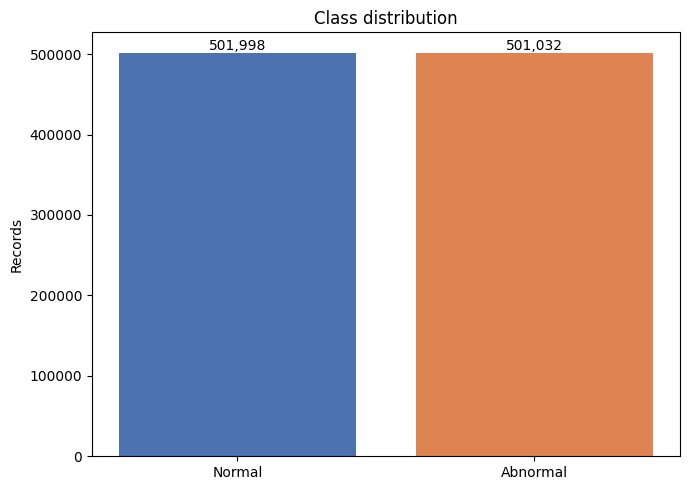

In [46]:
# Figure 1: record counts and class distribution
fig, ax = plt.subplots(figsize=(7, 5))

class_counts = CredGuard_IoT["label"].map({0: "Normal", 1: "Abnormal"}).value_counts()[["Normal", "Abnormal"]]
bars = ax.bar(class_counts.index, class_counts.values, color=["#4C72B0", "#DD8452"])
ax.bar_label(bars, labels=[f"{v:,}" for v in class_counts.values])
ax.set_title("Class distribution")
ax.set_ylabel("Records")

plt.tight_layout()
plt.show()

In [47]:
CredGuard_IoT.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1003030 entries, 0 to 1003029
Data columns (total 22 columns):
 #   Column               Non-Null Count    Dtype         
---  ------               --------------    -----         
 0   timestamp            1003030 non-null  datetime64[ns]
 1   src_ip               1003030 non-null  object        
 2   username             1003030 non-null  object        
 3   password             1003030 non-null  object        
 4   asn                  1003030 non-null  object        
 5   location             1003030 non-null  object        
 6   status               1003030 non-null  int64         
 7   label                1003030 non-null  int64         
 8   source               1003030 non-null  object        
 9   ip_type              1003030 non-null  object        
 10  iat                  1003030 non-null  float64       
 11  mean_iat             1003030 non-null  float64       
 12  std_iat              1003030 non-null  float64       
 1

In [48]:
CredGuard_IoT.head()

,timestamp,src_ip,username,password,asn,location,status,label,source,ip_type,iat,mean_iat,std_iat,login_attempt,fail_attempt,fail_ratio,password_length,password_complexity,day_of_week,hour,hour_sin,hour_cos
0,2021-02-18 06:42:07.939000,10.0.77.229,-4324475583306591935,Unknown,Internal Network,Internal_Network,0,0,df3,Private,43749.978000,1155.396195,5554.638102,28472,18171,0.638206,0.0,0.0,3,6,1.000000,6.123234e-17
1,2020-12-21 11:17:54.467000,84.209.238.191,-656805007504896862,Unknown,41164,NO,0,0,df3,Public,0.000000,0.000000,0.000000,1,1,1.000000,0.0,0.0,0,11,0.258819,-9.659258e-01
2,2021-01-08 04:14:45.494000,170.39.79.66,-4324475583306591935,Unknown,393398,US,0,0,df3,Public,1960.680000,13516.997292,20432.389126,2170,1572,0.724424,0.0,0.0,4,4,0.866025,5.000000e-01
3,2022-11-17 20:22:47.643075,177.207.207.172,nproc,nproc,18881,BR,0,1,df2,Public,1.768164,66.756877,36.819802,30,24,0.800000,5.0,1.0,3,20,-0.866025,5.000000e-01
4,2020-05-26 18:05:15.015000,79.161.211.206,-4324475583306591935,Unknown,29695,NO,0,0,df3,Public,33.882000,156964.905400,350155.397008,5,3,0.600000,0.0,0.0,1,18,-1.000000,-1.836970e-16


In [49]:
CredGuard_IoT.to_csv(OUTPUT_FILE, index=False)
print(f"saved: {OUTPUT_FILE}  {CredGuard_IoT.shape}")

saved: /kaggle/working/CredGuard_IoT.csv  (1003030, 22)
